# 04 - Decision Intelligence Framework

## Objective

The purpose of this notebook is to integrate the findings from the three machine learning models into a unified decision-support framework for global health policy.

Using Explainable Artificial Intelligence (SHAP), feature importance scores from the three outcome-specific models are combined to identify predictors that consistently influence multiple health outcomes.

The framework ranks health system and socioeconomic determinants according to their overall contribution to improving:

- Under-five mortality
- Maternal mortality
- Life expectancy at birth

The resulting Policy Priority Index provides an evidence-based ranking of health investment priorities that can support policymakers in allocating limited resources more effectively.

In [35]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [36]:
shap_u5 = pd.read_csv("../models/shap_u5.csv")

shap_maternal = pd.read_csv("../models/shap_maternal.csv")

shap_life = pd.read_csv("../models/shap_life.csv")

In [37]:
shap_life.head(10)

,Feature,SHAP Importance
0,UHC service coverage index,3.851429
1,Population growth (annual %),0.765985
2,"Physicians (per 1,000 people)",0.591989
3,People using safely managed drinking water ser...,0.470521
4,People using at least basic sanitation service...,0.466145
5,"Immunization, DPT (% of children ages 12-23 mo...",0.436257
6,Prevalence of anemia among children (% of chil...,0.285764
7,"Incidence of malaria (per 1,000 population at ...",0.256447
8,AIDS estimated deaths (UNAIDS estimates),0.182451
9,"Fertility rate, total (births per woman)",0.171907


In [38]:
shap_maternal.head(10)

,Feature,SHAP Importance
0,UHC service coverage index,58.385860
1,"Population, total",43.563976
2,"Immunization, DPT (% of children ages 12-23 mo...",42.702930
3,Births attended by skilled health staff (% of ...,36.545920
4,People using safely managed drinking water ser...,23.354317
5,"Tuberculosis case detection rate (%, all forms)",21.608454
6,Prevalence of hypertension (% of adults ages 3...,20.295800
7,People using at least basic sanitation service...,20.078299
8,"Incidence of tuberculosis (per 100,000 people)",19.379183
9,Age dependency ratio (% of working-age populat...,18.256512


In [39]:
shap_u5.head(10)

,Feature,SHAP Importance
0,UHC service coverage index,26.746011
1,Population growth (annual %),6.491806
2,"Immunization, DPT (% of children ages 12-23 mo...",4.305478
3,Prevalence of anemia among pregnant women (%),3.712085
4,Prevalence of anemia among children (% of chil...,3.098808
5,"Fertility rate, total (births per woman)",2.822933
6,"Adolescent fertility rate (births per 1,000 wo...",2.752788
7,Prevalence of anemia among women of reproducti...,1.663071
8,"Incidence of malaria (per 1,000 population at ...",0.946999
9,People using at least basic sanitation service...,0.867559


In [40]:
u5 = shap_u5.rename(
    columns={"SHAP Importance": "U5"}
)

maternal = shap_maternal.rename(
    columns={"SHAP Importance": "Maternal"}
)

life = shap_life.rename(
    columns={"SHAP Importance": "Life"}
)

In [41]:
priority = (
    u5
    .merge(maternal, on="Feature", how="outer")
    .merge(life, on="Feature", how="outer")
)

In [42]:
priority = priority.fillna(0)

In [43]:
priority.head(20)

,Feature,U5,Maternal,Life
0,AIDS estimated deaths (UNAIDS estimates),0.099291,3.763386,0.182451
1,"Adolescent fertility rate (births per 1,000 wo...",2.752788,10.644594,0.040421
2,Adults (ages 15+) and children (0-14 years) li...,0.099302,13.319696,0.099647
3,Adults (ages 15+) and children (ages 0-14) new...,0.148754,4.357439,0.035913
4,Age dependency ratio (% of working-age populat...,0.171077,18.256512,0.052174
5,"Age dependency ratio, old",0.415753,1.783472,0.014375
6,Antiretroviral therapy coverage (% of people l...,0.304128,1.421216,0.032171
7,Antiretroviral therapy coverage for PMTCT (% o...,0.130206,3.482475,0.021830
8,Births attended by skilled health staff (% of ...,0.237449,36.545920,0.009934
9,Children orphaned by HIV/AIDS,0.096246,2.184906,0.015501


In [44]:
priority["Policy_Priority_Index"] = (
    priority["U5"] +
    priority["Maternal"] +
    priority["Life"]
) / 3

In [45]:
policy_rank = priority.sort_values(
    "Policy_Priority_Index",
    ascending=False
)

policy_rank.head(20)

,Feature,U5,Maternal,Life,Policy_Priority_Index
70,UHC service coverage index,26.746011,58.385860,3.851429,29.661100
23,"Immunization, DPT (% of children ages 12-23 mo...",4.305478,42.702930,0.436257,15.814888
43,"Population, total",0.363435,43.563976,0.056361,14.661257
8,Births attended by skilled health staff (% of ...,0.237449,36.545920,0.009934,12.264434
36,People using safely managed drinking water ser...,0.667736,23.354317,0.470521,8.164191
68,"Tuberculosis case detection rate (%, all forms)",0.149785,21.608454,0.038614,7.265618
35,People using at least basic sanitation service...,0.867559,20.078299,0.466145,7.137334
49,Prevalence of hypertension (% of adults ages 3...,0.556734,20.295800,0.096883,6.983139
26,"Incidence of tuberculosis (per 100,000 people)",0.145156,19.379183,0.041438,6.521925
4,Age dependency ratio (% of working-age populat...,0.171077,18.256512,0.052174,6.159921


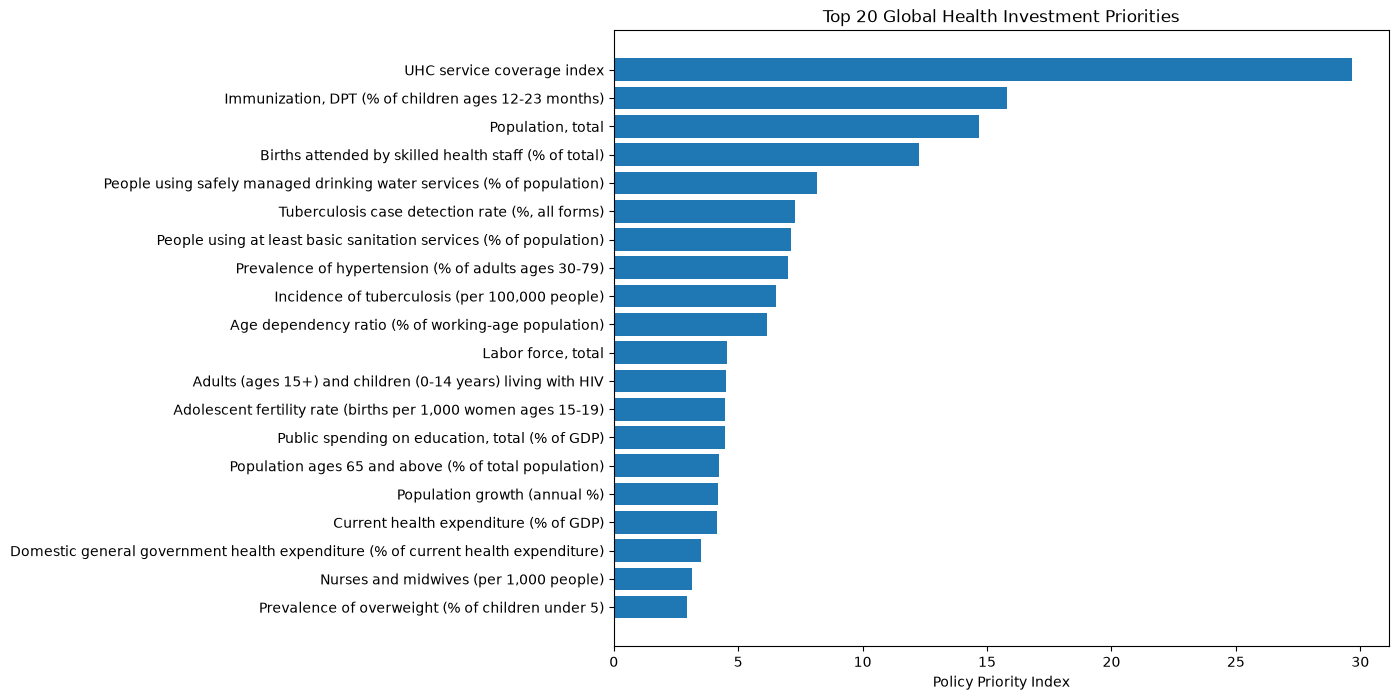

In [46]:
top20 = policy_rank.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"],
    top20["Policy_Priority_Index"]
)

plt.xlabel("Policy Priority Index")
plt.title("Top 20 Global Health Investment Priorities")

plt.gca().invert_yaxis()

plt.show()

In [47]:
scaler = MinMaxScaler()

priority[["U5_norm", "Maternal_norm", "Life_norm"]] = scaler.fit_transform(
    priority[["U5", "Maternal", "Life"]]
)

In [48]:
priority.head()

,Feature,U5,Maternal,Life,Policy_Priority_Index,U5_norm,Maternal_norm,Life_norm
0,AIDS estimated deaths (UNAIDS estimates),0.099291,3.763386,0.182451,1.348376,0.002080,0.063085,0.046362
1,"Adolescent fertility rate (births per 1,000 wo...",2.752788,10.644594,0.040421,4.479268,0.101453,0.181115,0.009446
2,Adults (ages 15+) and children (0-14 years) li...,0.099302,13.319696,0.099647,4.506215,0.002080,0.227000,0.024840
3,Adults (ages 15+) and children (ages 0-14) new...,0.148754,4.357439,0.035913,1.514035,0.003932,0.073275,0.008274
4,Age dependency ratio (% of working-age populat...,0.171077,18.256512,0.052174,6.159921,0.004768,0.311679,0.012501


In [49]:
priority["Policy_Priority_Index"] = (
    priority["U5_norm"] +
    priority["Maternal_norm"] +
    priority["Life_norm"]
) / 3

In [50]:
policy_rank = priority.sort_values(
    by="Policy_Priority_Index",
    ascending=False
)

policy_rank.head(20)

,Feature,U5,Maternal,Life,Policy_Priority_Index,U5_norm,Maternal_norm,Life_norm
70,UHC service coverage index,26.746011,58.385860,3.851429,1.000000,1.000000,1.000000,1.000000
23,"Immunization, DPT (% of children ages 12-23 mo...",4.305478,42.702930,0.436257,0.334310,0.159602,0.730998,0.112331
43,"Population, total",0.363435,43.563976,0.056361,0.257109,0.011972,0.745767,0.013589
8,Births attended by skilled health staff (% of ...,0.237449,36.545920,0.009934,0.211388,0.007254,0.625389,0.001522
36,People using safely managed drinking water ser...,0.667736,23.354317,0.470521,0.181242,0.023368,0.399120,0.121237
42,Population growth (annual %),6.491806,5.324211,0.765985,0.176457,0.241480,0.089857,0.198034
35,People using at least basic sanitation service...,0.867559,20.078299,0.466145,0.164626,0.030851,0.342927,0.120100
49,Prevalence of hypertension (% of adults ages 3...,0.556734,20.295800,0.096883,0.129997,0.019211,0.346658,0.024122
68,"Tuberculosis case detection rate (%, all forms)",0.149785,21.608454,0.038614,0.127374,0.003971,0.369174,0.008976
26,"Incidence of tuberculosis (per 100,000 people)",0.145156,19.379183,0.041438,0.114814,0.003797,0.330936,0.009710


In [51]:
top20 = policy_rank [
    ["Feature", "Policy_Priority_Index"]
].head(20)

top20

,Feature,Policy_Priority_Index
70,UHC service coverage index,1.000000
23,"Immunization, DPT (% of children ages 12-23 mo...",0.334310
43,"Population, total",0.257109
8,Births attended by skilled health staff (% of ...,0.211388
36,People using safely managed drinking water ser...,0.181242
42,Population growth (annual %),0.176457
35,People using at least basic sanitation service...,0.164626
49,Prevalence of hypertension (% of adults ages 3...,0.129997
68,"Tuberculosis case detection rate (%, all forms)",0.127374
26,"Incidence of tuberculosis (per 100,000 people)",0.114814


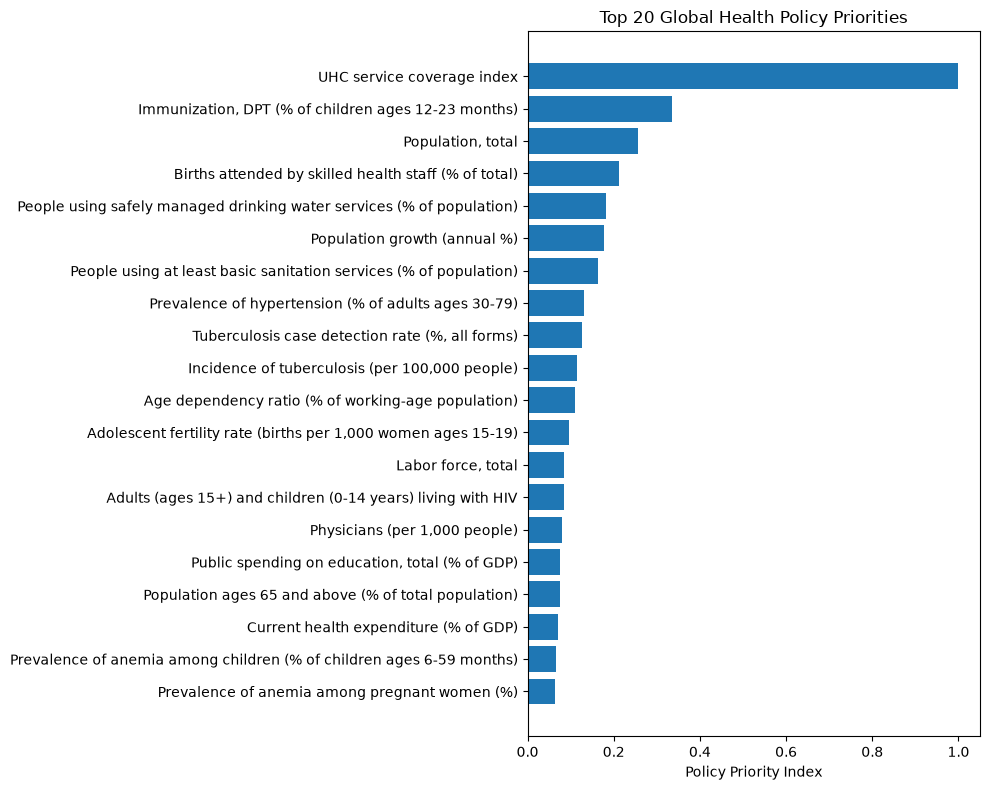

In [52]:
plt.figure(figsize=(10,8))

plt.barh(
    top20["Feature"][::-1],
    top20["Policy_Priority_Index"][::-1]
)

plt.xlabel("Policy Priority Index")
plt.title("Top 20 Global Health Policy Priorities")

plt.tight_layout()
plt.show()

In [53]:
policy_rank.to_csv(
    "../data/clean/Policy_Priority_Index.csv",
    index=False
)

In [54]:
top20.to_csv(
    "../data/clean/Top20_Policy_Priorities.csv",
    index=False
)

In [ ]:
domains = {

    # ==========================
    # Health System Strengthening
    # ==========================
    "UHC service coverage index": "Health System Strengthening",
    "Hospital beds (per 1,000 people)": "Health System Strengthening",

    # ==========================
    # Health Workforce
    # ==========================
    "Physicians (per 1,000 people)": "Health Workforce",
    "Nurses and midwives (per 1,000 people)": "Health Workforce",

    # ==========================
    # Health Financing
    # ==========================
    "Current health expenditure (% of GDP)": "Health Financing",
    "Current health expenditure per capita (current US$)": "Health Financing",
    "Current health expenditure per capita, PPP (current international $)": "Health Financing",
    "Domestic general government health expenditure (% of GDP)": "Health Financing",
    "Domestic general government health expenditure (% of current health expenditure)": "Health Financing",
    "Domestic general government health expenditure (% of general government expenditure)": "Health Financing",
    "Domestic private health expenditure (% of current health expenditure)": "Health Financing",
    "External health expenditure (% of current health expenditure)": "Health Financing",
    "External health expenditure channeled through government (% of external health expenditure)": "Health Financing",
    "Out-of-pocket expenditure (% of current health expenditure)": "Health Financing",
    "Risk of catastrophic expenditure for surgical care (% of people at risk)": "Health Financing",
    "Risk of impoverishing expenditure for surgical care (% of people at risk)": "Health Financing",

    # ==========================
    # Maternal & Child Health
    # ==========================
    "Births attended by skilled health staff (% of total)": "Maternal & Child Health",
    "Immunization, DPT (% of children ages 12-23 months)": "Maternal & Child Health",
    "Exclusive breastfeeding (% of children under 6 months)": "Maternal & Child Health",
    "Newborns protected against tetanus (%)": "Maternal & Child Health",
    "Low-birthweight babies (% of births)": "Maternal & Child Health",
    "Vitamin A supplementation coverage rate (% of children ages 6-59 months)": "Maternal & Child Health",
    "Adolescent fertility rate (births per 1,000 women ages 15-19)": "Maternal & Child Health",
    "Fertility rate, total (births per woman)": "Maternal & Child Health",

    # ==========================
    # Nutrition
    # ==========================
    "Prevalence of anemia among children (% of children ages 6-59 months)": "Nutrition",
    "Prevalence of anemia among pregnant women (%)": "Nutrition",
    "Prevalence of anemia among women of reproductive age (% of women ages 15-49)": "Nutrition",
    "Prevalence of undernourishment (% of population)": "Nutrition",
    "Prevalence of wasting, weight for height (% of children under 5)": "Nutrition",
    "Prevalence of severe wasting, weight for height (% of children under 5)": "Nutrition",
    "Prevalence of underweight, weight for age (% of children under 5)": "Nutrition",
    "Prevalence of stunting, height for age (% of children under 5)": "Nutrition",
    "Prevalence of overweight (% of children under 5)": "Nutrition",

    # ==========================
    # WASH
    # ==========================
    "People using safely managed drinking water services (% of population)": "WASH",
    "People using safely managed sanitation services (% of population)": "WASH",
    "People using at least basic drinking water services (% of population)": "WASH",
    "People using at least basic sanitation services (% of population)": "WASH",
    "People with basic handwashing facilities including soap and water (% of population)": "WASH",
    "People practicing open defecation (% of population)": "WASH",

    # ==========================
    # Infectious Disease Control
    # ==========================
    "Adults (ages 15+) and children (0-14 years) living with HIV": "Infectious Disease Control",
    "Adults (ages 15+) and children (ages 0-14) newly infected with HIV": "Infectious Disease Control",
    "AIDS estimated deaths (UNAIDS estimates)": "Infectious Disease Control",
    "Incidence of HIV, all (per 1,000 uninfected population)": "Infectious Disease Control",
    "Antiretroviral therapy coverage (% of people living with HIV)": "Infectious Disease Control",
    "Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)": "Infectious Disease Control",
    "Children orphaned by HIV/AIDS": "Infectious Disease Control",
    "Incidence of tuberculosis (per 100,000 people)": "Infectious Disease Control",
    "Tuberculosis case detection rate (%, all forms)": "Infectious Disease Control",
    "Tuberculosis treatment success rate (% of new cases)": "Infectious Disease Control",
    "Incidence of malaria (per 1,000 population at risk)": "Infectious Disease Control",
    "Prevalence of HIV, total (% of population ages 15-49)": "Infectious Disease Control",
    "Prevalence of syphilis (% of women attending antenatal care)": "Infectious Disease Control",

    # ==========================
    # Non-Communicable Diseases
    # ==========================
    "Prevalence of hypertension (% of adults ages 30-79)": "Non-Communicable Diseases",
    "Treatment for hypertension (% of adults ages 30-79 with hypertension)": "Non-Communicable Diseases",
    "Prevalence of current tobacco use (% of adults)": "Non-Communicable Diseases",
    "Prevalence of overweight (% of adults)": "Non-Communicable Diseases",
    "Total alcohol consumption per capita (liters of pure alcohol, projected estimates, 15+ years of age)": "Non-Communicable Diseases",

    # ==========================
    # Education
    # ==========================
    "Public spending on education, total (% of GDP)": "Education",
    "Primary completion rate, total (% of relevant age group)": "Education",
    "School enrollment, primary (% net)": "Education",
    "School enrollment, secondary (% net)": "Education",
    "School enrollment, tertiary (% gross)": "Education",

    # ==========================
    # Demographics
    # ==========================
    "Population, total": "Demographics",
    "Population growth (annual %)": "Demographics",
    "Population ages 0-14 (% of total population)": "Demographics",
    "Population ages 65 and above (% of total population)": "Demographics",
    "Age dependency ratio (% of working-age population)": "Demographics",
    "Age dependency ratio, old": "Demographics",
    "Labor force, total": "Demographics",
    "Net migration": "Demographics",
    "Urban population (% of total population)": "Demographics",
    "Rural population (% of total population)": "Demographics",
    "Year": "Demographics",

    # ==========================
    # Economic Development
    # ==========================
    "GNI per capita, Atlas method (current US$)": "Economic Development",
    "Unemployment, total (% of total labor force)": "Economic Development"}

In [56]:
policy_rank["Domain"] = policy_rank["Feature"].map(domains)

In [57]:
policy_rank[policy_rank["Domain"].isna()][["Feature"]]

,Feature


In [58]:
domain_rank = (
    policy_rank
    .groupby("Domain", as_index=False)["Policy_Priority_Index"]
    .sum()
    .sort_values("Policy_Priority_Index", ascending=False)
)

domain_rank

,Domain,Policy_Priority_Index
4,Health System Strengthening,1.009306
0,Demographics,0.810768
7,Maternal & Child Health,0.782005
6,Infectious Disease Control,0.557212
10,WASH,0.443572
3,Health Financing,0.284400
9,Nutrition,0.272169
8,Non-Communicable Diseases,0.196851
2,Education,0.190841
5,Health Workforce,0.138973


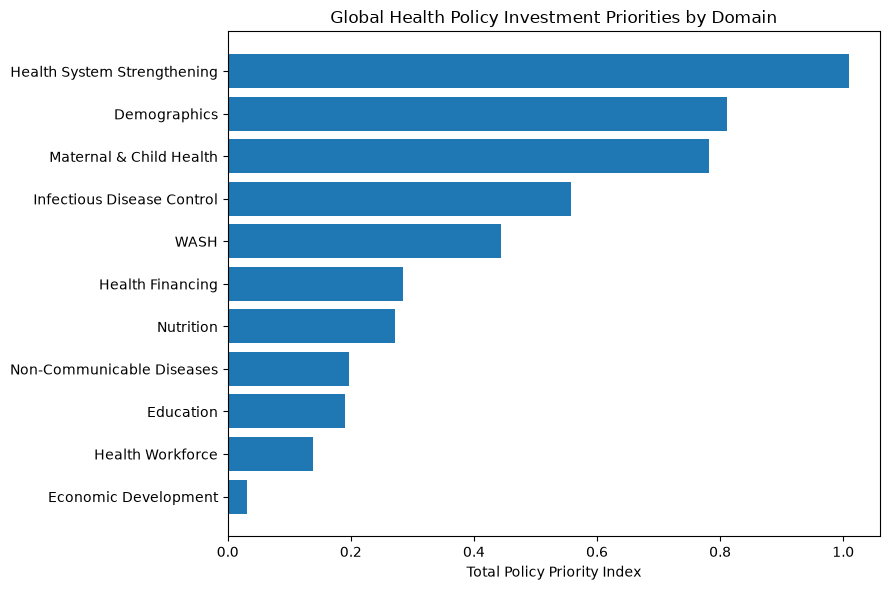

In [59]:
plt.figure(figsize=(9,6))

plt.barh(
    domain_rank["Domain"][::-1],
    domain_rank["Policy_Priority_Index"][::-1]
)

plt.xlabel("Total Policy Priority Index")
plt.title("Global Health Policy Investment Priorities by Domain")

plt.tight_layout()
plt.show()

In [ ]:
domain_rank.to_csv(
    "../data/clean/policy_priority_index_domains.csv",
    index=False
)

## Outcome-Specific Policy Priority Rankings

Although the combined Policy Priority Index identifies predictors that matter across all three outcomes, policy decisions may also require outcome-specific priorities.

This section ranks predictors separately for:

- Under-five mortality
- Maternal mortality
- Life expectancy

This allows policymakers to identify whether a determinant is mainly important for one outcome or consistently important across several outcomes.

In [61]:
u5_rank = priority[
    ["Feature", "U5", "U5_norm"]
].sort_values(
    by="U5_norm",
    ascending=False
)

maternal_rank = priority[
    ["Feature", "Maternal", "Maternal_norm"]
].sort_values(
    by="Maternal_norm",
    ascending=False
)

life_rank = priority[
    ["Feature", "Life", "Life_norm"]
].sort_values(
    by="Life_norm",
    ascending=False
)

In [62]:
u5_rank.head(20)

,Feature,U5,U5_norm
70,UHC service coverage index,26.746011,1.000000
42,Population growth (annual %),6.491806,0.241480
23,"Immunization, DPT (% of children ages 12-23 mo...",4.305478,0.159602
46,Prevalence of anemia among pregnant women (%),3.712085,0.137379
45,Prevalence of anemia among children (% of chil...,3.098808,0.114412
20,"Fertility rate, total (births per woman)",2.822933,0.104080
1,"Adolescent fertility rate (births per 1,000 wo...",2.752788,0.101453
47,Prevalence of anemia among women of reproducti...,1.663071,0.060643
25,"Incidence of malaria (per 1,000 population at ...",0.946999,0.033827
35,People using at least basic sanitation service...,0.867559,0.030851


In [63]:
maternal_rank.head(20)

,Feature,Maternal,Maternal_norm
70,UHC service coverage index,58.385860,1.000000
43,"Population, total",43.563976,0.745767
23,"Immunization, DPT (% of children ages 12-23 mo...",42.702930,0.730998
8,Births attended by skilled health staff (% of ...,36.545920,0.625389
36,People using safely managed drinking water ser...,23.354317,0.399120
68,"Tuberculosis case detection rate (%, all forms)",21.608454,0.369174
49,Prevalence of hypertension (% of adults ages 3...,20.295800,0.346658
35,People using at least basic sanitation service...,20.078299,0.342927
26,"Incidence of tuberculosis (per 100,000 people)",19.379183,0.330936
4,Age dependency ratio (% of working-age populat...,18.256512,0.311679


In [64]:
life_rank.head(20)

,Feature,Life,Life_norm
70,UHC service coverage index,3.851429,1.000000
42,Population growth (annual %),0.765985,0.198034
39,"Physicians (per 1,000 people)",0.591989,0.152809
36,People using safely managed drinking water ser...,0.470521,0.121237
35,People using at least basic sanitation service...,0.466145,0.120100
23,"Immunization, DPT (% of children ages 12-23 mo...",0.436257,0.112331
45,Prevalence of anemia among children (% of chil...,0.285764,0.073215
25,"Incidence of malaria (per 1,000 population at ...",0.256447,0.065595
0,AIDS estimated deaths (UNAIDS estimates),0.182451,0.046362
20,"Fertility rate, total (births per woman)",0.171907,0.043622


In [65]:
u5_rank["Domain"] = u5_rank["Feature"].map(domains)

maternal_rank["Domain"] = maternal_rank["Feature"].map(domains)

life_rank["Domain"] = life_rank["Feature"].map(domains)

In [66]:
u5_rank[u5_rank["Domain"].isna()][["Feature"]]

,Feature


In [67]:
maternal_rank[maternal_rank["Domain"].isna()][["Feature"]]

,Feature


In [68]:
life_rank[life_rank["Domain"].isna()][["Feature"]]

,Feature


In [69]:
u5_domain_rank = (
    u5_rank
    .groupby("Domain", as_index=False)["U5_norm"]
    .sum()
    .sort_values("U5_norm", ascending=False)
)

maternal_domain_rank = (
    maternal_rank
    .groupby("Domain", as_index=False)["Maternal_norm"]
    .sum()
    .sort_values("Maternal_norm", ascending=False)
)

life_domain_rank = (
    life_rank
    .groupby("Domain", as_index=False)["Life_norm"]
    .sum()
    .sort_values("Life_norm", ascending=False)
)

In [70]:
u5_domain_rank

,Domain,U5_norm
4,Health System Strengthening,1.004345
7,Maternal & Child Health,0.406603
9,Nutrition,0.334088
0,Demographics,0.328377
10,WASH,0.084151
6,Infectious Disease Control,0.082666
8,Non-Communicable Diseases,0.039996
2,Education,0.037922
3,Health Financing,0.031726
5,Health Workforce,0.028848


In [71]:
maternal_domain_rank

,Domain,Maternal_norm
0,Demographics,1.818696
7,Maternal & Child Health,1.765585
6,Infectious Disease Control,1.366802
4,Health System Strengthening,1.021615
10,WASH,0.995505
3,Health Financing,0.792374
2,Education,0.498846
8,Non-Communicable Diseases,0.490159
9,Nutrition,0.333151
5,Health Workforce,0.221787


In [72]:
life_domain_rank

,Domain,Life_norm
4,Health System Strengthening,1.001958
0,Demographics,0.285230
10,WASH,0.251059
6,Infectious Disease Control,0.222167
7,Maternal & Child Health,0.173826
5,Health Workforce,0.166285
9,Nutrition,0.149268
8,Non-Communicable Diseases,0.060397
2,Education,0.035755
3,Health Financing,0.029099


In [73]:
u5_rank.to_csv("../data/clean/u5_policy_priority_ranking.csv", index=False)

maternal_rank.to_csv("../data/clean/maternal_policy_priority_ranking.csv", index=False)

life_rank.to_csv("../data/clean/life_policy_priority_ranking.csv", index=False)

u5_domain_rank.to_csv("../data/clean/u5_domain_priority_ranking.csv", index=False)

maternal_domain_rank.to_csv("../data/clean/maternal_domain_priority_ranking.csv", index=False)

life_domain_rank.to_csv("../data/clean/life_domain_priority_ranking.csv", index=False)

policy_rank.to_csv("../data/clean/combined_policy_priority_index.csv", index=False)

domain_rank.to_csv("../data/clean/combined_domain_priority_ranking.csv", index=False)

In [75]:
import joblib

joblib.dump(shap_u5, "../models/shap_u5.pkl")

joblib.dump(shap_maternal, "../models/shap_maternal.pkl")

joblib.dump(shap_life, "../models/shap_life.pkl")

['../models/shap_life.pkl']